# Demo 1 · Quantum state preparation

Starting from $|00\rangle$, the DQN chooses gates for a specified target under an eight-gate budget. This notebook loads the final checkpoints and compares the greedy policy with the random baseline on the six training targets.

Set `experiment_dir` in the first cell to the directory containing `selected_checkpoints.json` and `demo1_results.json`. Keep the checkpoint paths relative to that directory.

In [ ]:
import json
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from qprep.actions import serialise_action_catalogue
from qprep.dqn import QNetwork, select_action
from qprep.environment import QuantumEnv
from qprep.evaluate import evaluate_policy
from qprep.rollout import rollout
from qprep.targets import REFERENCE_ACTIONS
from qprep.visualise import draw_circuit, plot_comparison, plot_learning, step_table

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

experiment_dir = project_root / "runs" / "demo1-main"

manifest = json.loads(
    (experiment_dir / "selected_checkpoints.json").read_text(encoding="utf-8")
)
results = json.loads(
    (experiment_dir / "demo1_results.json").read_text(encoding="utf-8")
)
models = {model["seed"]: model for model in manifest["models"]}

Matplotlib is building the font cache; this may take a moment.


## Success and circuit length

The DQN is evaluated once per seed and target. Random success is measured across 100 attempts per target. Known reference circuits provide a concrete comparison for the gate counts.

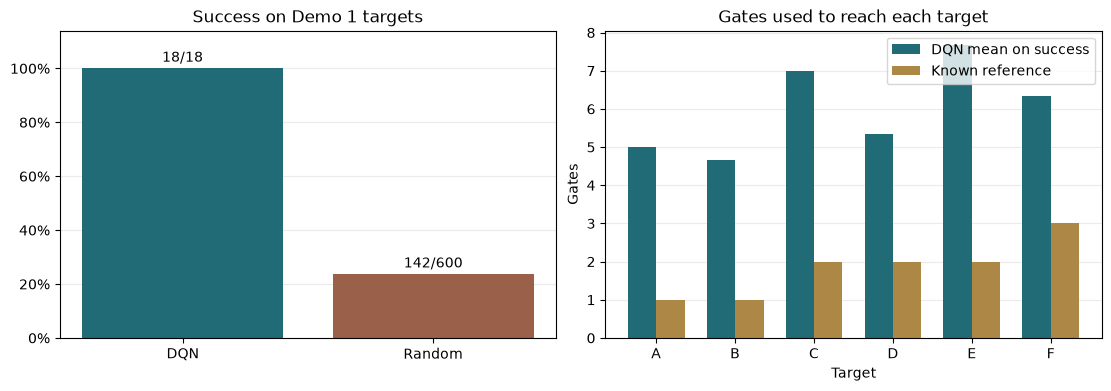

Seed 0: 6/6 successes in 330.1 s of training
Seed 1: 6/6 successes in 588.3 s of training
Seed 2: 6/6 successes in 587.2 s of training
Median action-selection time per attempt: 1.67 ms


In [2]:
figure = plot_comparison(results)
display(figure)
plt.close(figure)

for row in results["per_seed"]:
    print(
        f"Seed {row['seed']}: {row['successes']}/{row['attempts']} successes "
        f"in {row['training_seconds']:.1f} s of training"
    )

policy_times = [row["inference_ms"] for row in results["attempts"]]
print(f"Median action-selection time per attempt: {np.median(policy_times):.2f} ms")

## Inspect a saved policy

The default examples cover a product state, a phase-sensitive state, and an entangled state. Add `"zero"` to show the case where the starting state already satisfies the goal.

### Target B · seed 0

**Success** · fidelity 1.000000 · 5 gates · known reference 1 gates

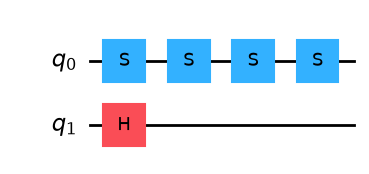

| Gates used | Operation | Fidelity | Reward |
| ---: | :--- | ---: | ---: |
| 0 | Start | 0.500000 | — |
| 1 | S(q0) | 0.500000 | -0.05 |
| 2 | S(q0) | 0.500000 | -0.05 |
| 3 | S(q0) | 0.500000 | -0.05 |
| 4 | S(q0) | 0.500000 | -0.05 |
| 5 | H(q1) | 1.000000 | 9.95 |

### Target D · seed 0

**Success** · fidelity 1.000000 · 2 gates · known reference 2 gates

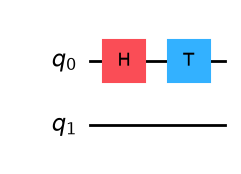

| Gates used | Operation | Fidelity | Reward |
| ---: | :--- | ---: | ---: |
| 0 | Start | 0.500000 | — |
| 1 | H(q0) | 0.853553 | -0.05 |
| 2 | T(q0) | 1.000000 | 9.95 |

### Target E · seed 0

**Success** · fidelity 1.000000 · 8 gates · known reference 2 gates

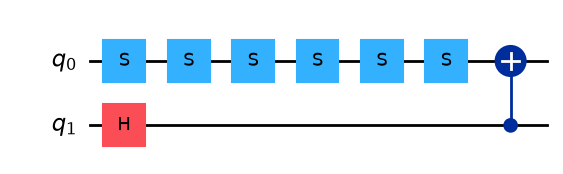

| Gates used | Operation | Fidelity | Reward |
| ---: | :--- | ---: | ---: |
| 0 | Start | 0.500000 | — |
| 1 | S(q0) | 0.500000 | -0.05 |
| 2 | S(q0) | 0.500000 | -0.05 |
| 3 | S(q0) | 0.500000 | -0.05 |
| 4 | S(q0) | 0.500000 | -0.05 |
| 5 | S(q0) | 0.500000 | -0.05 |
| 6 | S(q0) | 0.500000 | -0.05 |
| 7 | H(q1) | 0.250000 | -0.05 |
| 8 | CX(q1 → q0) | 1.000000 | 9.95 |

In [3]:
seed = 0
target_ids = ["B", "D", "E"]

model = models[seed]
checkpoint = torch.load(
    experiment_dir / model["checkpoint"], map_location="cpu", weights_only=True
)
if checkpoint["provenance"]["seed"] != seed:
    raise ValueError("The checkpoint seed differs from the selected seed.")
if checkpoint["action_catalogue"] != serialise_action_catalogue():
    raise ValueError("The checkpoint action catalogue differs from the current one.")

config = checkpoint["config"]
network = QNetwork(config)
network.load_state_dict(checkpoint["online_network_state"])
network.eval()
rng = np.random.default_rng(seed)

evaluation = evaluate_policy(network, config, rng)
if evaluation != checkpoint["evaluation"]:
    raise ValueError("Reloaded evaluation differs from the saved evaluation.")

by_target = {row["target_id"]: row for row in evaluation}

def greedy_policy(observation):
    return select_action(network, observation, epsilon=0, rng=rng)

for target_id in target_ids:
    if target_id == "zero":
        trace = asdict(
            rollout(QuantumEnv(config), greedy_policy, target_id="zero")
        )
        final_fidelity = trace["initial_fidelity"]
        reference_count = 0
    else:
        result = by_target[target_id]
        trace = result["trace"]
        final_fidelity = result["final_fidelity"]
        reference_count = len(REFERENCE_ACTIONS[target_id])

    outcome = trace["end_reason"].replace("_", " ")
    display(Markdown(
        f"### Target {target_id} · seed {seed}\n\n"
        f"**{outcome.capitalize()}** · fidelity {final_fidelity:.6f} · "
        f"{len(trace['steps'])} gates · known reference {reference_count} gates"
    ))
    figure = draw_circuit(trace)
    display(figure)
    plt.close(figure)
    display(Markdown(step_table(trace)))

## Training progress

These curves use completed episodes from the training logs. They include exploration, which changes as epsilon falls. A resumed run's final log segment is labelled with its starting step.

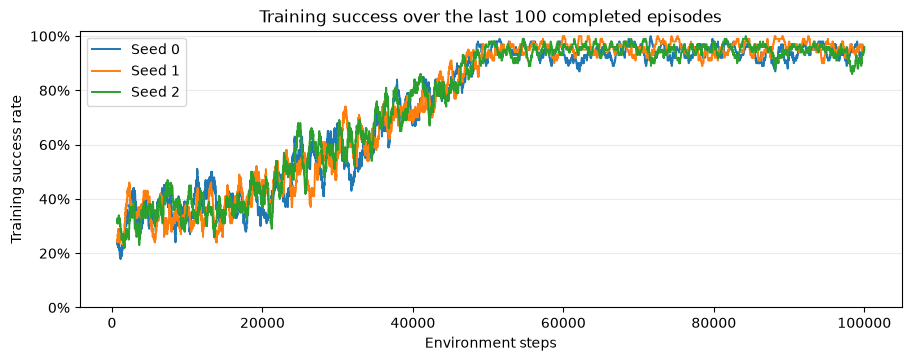

In [4]:
figure = plot_learning(experiment_dir, manifest["models"])
display(figure)
plt.close(figure)